In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import OLSInfluence
from sklearn.model_selection import train_test_split
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [2]:
df = pd.read_csv("../data/processed/model_data_final.csv")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

print("Shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("\nFlagged high-leverage months:")
print(df.loc[df["LeverageNote"].notna(), ["Date", "LeverageNote"]])

df.head()

Shape: (220, 7)
Date range: 2008-02-01 00:00:00 to 2026-05-01 00:00:00

Flagged high-leverage months:
          Date                                       LeverageNote
9   2008-11-01                      High Cook's D / high residual
21  2009-11-01                              High Cook's D (0.039)
22  2009-12-01                              GasPrices base-effect
23  2010-01-01                              GasPrices base-effect
146 2020-04-01                             COVID stimulus/outlier
154 2020-12-01                              High Cook's D (0.036)
155 2021-01-01                                           Stimulus
156 2021-02-01                      High Cook's D, driver unclear
157 2021-03-01                                           Stimulus
158 2021-04-01  AR residual echo, highest Cook's D in final mo...
160 2021-06-01                              High Cook's D (0.028)
164 2021-10-01                              High Cook's D (0.040)
165 2021-11-01                          

,Date,RealWageGrowth,GasPrices_YoY,RealMortgageRate,DisposableIncome_YoY,RealWageGrowth_Lag1,LeverageNote
0,2008-02-01,-1.29,32.92,1.78,0.25,-1.38,NaN
1,2008-03-01,-0.88,26.57,2.00,-0.04,-1.29,NaN
2,2008-04-01,-1.06,21.55,2.02,-0.55,-0.88,NaN
3,2008-05-01,-1.07,19.71,1.95,4.28,-1.06,NaN
4,2008-06-01,-2.22,32.66,1.38,1.72,-1.07,NaN




# Baseline OLS (Model A) -- interpretation




In [3]:
TARGET = "RealWageGrowth"
PREDICTORS = ["GasPrices_YoY", "RealMortgageRate", "DisposableIncome_YoY"]

x = sm.add_constant(df[PREDICTORS])
y = df[TARGET]

baseline_model = sm.OLS(y, x).fit()
print(baseline_model.summary())

                            OLS Regression Results                            
Dep. Variable:         RealWageGrowth   R-squared:                       0.735
Model:                            OLS   Adj. R-squared:                  0.731
Method:                 Least Squares   F-statistic:                     199.6
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           5.33e-62
Time:                        13:17:56   Log-Likelihood:                -285.92
No. Observations:                 220   AIC:                             579.8
Df Residuals:                     216   BIC:                             593.4
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    0.2729 

Durbin Watson indicates severe autocorrelation, motivating the AR-augmented version next.

# AR-augmented OLS (Model B) -- forecasting

In [4]:
PREDICTORS_AR = PREDICTORS + ["RealWageGrowth_Lag1"]

x_ar = sm.add_constant(df[PREDICTORS_AR])
y_ar = df[TARGET]

ar_model = sm.OLS(y_ar, x_ar).fit()
print(ar_model.summary())

                            OLS Regression Results                            
Dep. Variable:         RealWageGrowth   R-squared:                       0.886
Model:                            OLS   Adj. R-squared:                  0.884
Method:                 Least Squares   F-statistic:                     418.1
Date:                Mon, 12 Oct 2026   Prob (F-statistic):          3.71e-100
Time:                        13:17:56   Log-Likelihood:                -193.03
No. Observations:                 220   AIC:                             396.1
Df Residuals:                     215   BIC:                             413.0
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    0.2127 

In [5]:
residuals = ar_model.resid
worst = residuals.abs().sort_values(ascending=False).head(10)
print(df.loc[worst.index, ["Date", TARGET, "RealWageGrowth_Lag1", "LeverageNote"]].assign(Residual=worst))

          Date  RealWageGrowth  RealWageGrowth_Lag1  \
146 2020-04-01            7.79                 1.97   
158 2021-04-01           -3.53                 1.85   
9   2008-11-01            2.40                -0.41   
160 2021-06-01           -1.35                -2.60   
179 2023-01-01           -1.84                -1.46   
154 2020-12-01            4.07                 3.41   
157 2021-03-01            1.85                 3.62   
163 2021-09-01           -0.37                -0.78   
4   2008-06-01           -2.22                -1.07   
24  2010-02-01            0.03                -0.62   

                                          LeverageNote  Residual  
146                             COVID stimulus/outlier  4.840174  
158  AR residual echo, highest Cook's D in final mo...  3.303728  
9                        High Cook's D / high residual  1.469718  
160                              High Cook's D (0.028)  1.317521  
179        Disinflation/rate-hike (candidate Regime 4)  1.2

RealMortgageRate loses significance entirely with the introduction of the AR-term, residuals point to April 2020 & 2021 as outliers.

# Regularization

In [6]:
def run_regularization(x_cols, label):
    x_raw = df[x_cols]
    y = df[TARGET]

    scaler = StandardScaler()
    x_scaled = scaler.fit_transform(x_raw)

    ridge = RidgeCV(alphas=np.logspace(-3, 3, 50)).fit(x_scaled, y)
    lasso = LassoCV(alphas=np.logspace(-3, 3, 50), max_iter=10000).fit(x_scaled, y)

    comparison = pd.DataFrame({
        "OLS": np.asarray(sm.OLS(y, sm.add_constant(x_scaled)).fit().params)[1:],
        "Ridge": ridge.coef_,
        "Lasso": lasso.coef_
    }, index=x_cols)

    print(f"--- {label} ---")
    print(f"Ridge alpha: {ridge.alpha_:.4f}, Lasso alpha: {lasso.alpha_:.4f}")
    print(comparison)
    print()

run_regularization(PREDICTORS, "Model A (baseline)")
run_regularization(PREDICTORS_AR, "Model B (AR-augmented)")

--- Model A (baseline) ---
Ridge alpha: 8.2864, Lasso alpha: 0.2812
                           OLS     Ridge     Lasso
GasPrices_YoY        -1.041323 -0.983248 -0.935174
RealMortgageRate      0.337273  0.367179  0.192337
DisposableIncome_YoY  0.372834  0.369732  0.167808

--- Model B (AR-augmented) ---
Ridge alpha: 6.2506, Lasso alpha: 0.1600
                           OLS     Ridge     Lasso
GasPrices_YoY        -0.577102 -0.566934 -0.521160
RealMortgageRate      0.060630  0.093378  0.000000
DisposableIncome_YoY  0.146871  0.157196  0.036546
RealWageGrowth_Lag1   1.042465  0.995439  1.010579



All three columns use standardized predictors, so the coefficients are directly comparable. Ridge barely moves anything from OLS, which means multicollinearity isn't distorting the estimates. Lasso is more telling: in Model B it shrinks RealMortgageRate to exactly zero and cuts DisposableIncome_YoY by about 75%, an early sign of the two variables later dropped from the final model.

# Split-sample validation

In [7]:
# Chronological train/test split
# 80/20 split
split_idx = int(len(df) * 0.8)
train, test = df.iloc[:split_idx], df.iloc[split_idx:]

print(f"Train: {train["Date"].min()} to {train["Date"].max()} ({len(train)} obs)")
print(f"Test: {test["Date"].min()} to {test["Date"].max()} ({len(test)} obs)")

Train: 2008-02-01 00:00:00 to 2022-09-01 00:00:00 (176 obs)
Test: 2022-10-01 00:00:00 to 2026-05-01 00:00:00 (44 obs)


In [8]:
# Model A coefficient stability check
x_train_a = sm.add_constant(train[PREDICTORS])
model_a_train = sm.OLS(train[TARGET], x_train_a).fit()

coef_comparison = pd.DataFrame({
    "Full Sample": baseline_model.params,
    "Train Only": model_a_train.params
})
print("Model A coefficient stability:")
print(coef_comparison)

# Model B out of sample forecast accuracy
x_train_b = sm.add_constant(train[PREDICTORS_AR])
x_test_b = sm.add_constant(test[PREDICTORS_AR])
model_b_train = sm.OLS(train[TARGET], x_train_b).fit()

pred_b = model_b_train.predict(x_test_b)
rmse_b = np.sqrt(mean_squared_error(test[TARGET], pred_b))
mae_b = mean_absolute_error(test[TARGET], pred_b)

# Predict this period using last period's actual value
pred = test[TARGET].shift(1)
pred.iloc[0] = train[TARGET].iloc[-1] # first test prediction uses last train value
rmse_pred = np.sqrt(mean_squared_error(test[TARGET], pred))
mae_pred = mean_absolute_error(test[TARGET], pred)

# Model A out of sample for comparison
x_test_a = sm.add_constant(test[PREDICTORS])
pred_a = model_a_train.predict(x_test_a)
rmse_a = np.sqrt(mean_squared_error(test[TARGET], pred_a))
mae_a = mean_absolute_error(test[TARGET], pred_a)

print("\nOut of sample performance:")
print(pd.DataFrame({
    "RMSE": [rmse_pred, rmse_a, rmse_b],
    "MAE": [mae_pred, mae_a, mae_b]
}, index=["Persistence", "Model A (baseline)", "Model B (AR-augmented)"]))

Model A coefficient stability:
                      Full Sample  Train Only
const                    0.272878    0.601363
GasPrices_YoY           -0.045373   -0.053437
RealMortgageRate         0.168576    0.082127
DisposableIncome_YoY     0.098248    0.110142

Out of sample performance:
                            RMSE       MAE
Persistence             0.444200  0.331818
Model A (baseline)      1.117007  0.774563
Model B (AR-augmented)  0.500688  0.377682


# Redundancy Check

In [9]:
#  Sequential redundancy check regarding RealMortgageRate
PREDICTORS_NO_MTG = ["GasPrices_YoY", "DisposableIncome_YoY"]
PREDICTORS_AR_NO_MTG = PREDICTORS_NO_MTG + ["RealWageGrowth_Lag1"]

def compare_with_without(full_cols, reduced_cols, label):
    x_full = sm.add_constant(train[full_cols])
    x_reduced = sm.add_constant(train[reduced_cols])

    m_full = sm.OLS(train[TARGET], x_full).fit()
    m_reduced = sm.OLS(train[TARGET], x_reduced).fit()

    pred_full = m_full.predict(sm.add_constant(test[full_cols]))
    pred_reduced = m_reduced.predict(sm.add_constant(test[reduced_cols]))

    rmse_full = np.sqrt(mean_squared_error(test[TARGET], pred_full))
    rmse_reduced = np.sqrt(mean_squared_error(test[TARGET], pred_reduced))

    print(f"-- {label} --")
    print(f"{'':20s} {"AIC":>10s} {"BIC":>10s} {"OOS RMSE":>10s}")
    print(f"{"Full":20s} {m_full.aic:10.2f} {m_full.bic:10.2f} {rmse_full:10.4f}")
    print(f"{"Reduced":20s} {m_reduced.aic:10.2f} {m_reduced.bic:10.2f} {rmse_reduced:10.4f}")
    print()

# Test 1: drop RealMortgageRate from Model A
compare_with_without(PREDICTORS, PREDICTORS_NO_MTG, "Model A: with vs without RealMortgageRate")

# Test 2: drop RealMortgageRate from Model B
compare_with_without(PREDICTORS_AR, PREDICTORS_AR_NO_MTG, "Model B: with vs without RealMortgageRate")

# Test 3: drop GasPrices_YoY instead, as a control (expected to clearly hurt the model)
PREDICTORS_NO_GAS = ["RealMortgageRate", "DisposableIncome_YoY"]
compare_with_without(PREDICTORS, PREDICTORS_NO_GAS, "Mirror test: with vs without GasPrices_YoY")

-- Model A: with vs without RealMortgageRate --
                            AIC        BIC   OOS RMSE
Full                     449.73     462.41     1.1170
Reduced                  450.58     460.09     1.1738

-- Model B: with vs without RealMortgageRate --
                            AIC        BIC   OOS RMSE
Full                     336.75     352.60     0.5007
Reduced                  334.94     347.62     0.5055

-- Mirror test: with vs without GasPrices_YoY --
                            AIC        BIC   OOS RMSE
Full                     449.73     462.41     1.1170
Reduced                  567.04     576.55     0.8826



In [10]:
x_full_a = sm.add_constant(train[PREDICTORS])
x_test_full_a = sm.add_constant(test[PREDICTORS])
m_full_a = sm.OLS(train[TARGET], x_full_a).fit()
pred_full_a = m_full_a.predict(x_test_full_a)

residual_check = pd.DataFrame({
    "Date": test["Date"],
    "Actual": test[TARGET],
    "Predicted": pred_full_a,
    "AbsError": (test[TARGET] - pred_full_a).abs()
}).sort_values("AbsError", ascending=False)

print(residual_check.head(10))

          Date  Actual  Predicted  AbsError
179 2023-01-01   -1.84   0.951169  2.791169
181 2023-03-01   -0.30   2.320873  2.620873
180 2023-02-01   -1.19   1.270992  2.460992
182 2023-04-01   -0.35   1.970327  2.320327
183 2023-05-01    0.23   2.512410  2.282410
176 2022-10-01   -2.75  -0.561123  2.188877
178 2022-12-01   -1.46   0.655017  2.115017
177 2022-11-01   -2.03  -0.075117  1.954883
184 2023-06-01    1.59   3.067480  1.477480
185 2023-07-01    1.38   2.587657  1.207657



*   RealMortgageRate's redundancy is model specific, specifically once the AR term absorbs its signal
*   The mirror test confirms GasPrices_YoY is essential by AIC/BIC, but contradicts that on OOS RMSE, and that contradiction is the most important thing in this cell.
*   Model A's worst residuals cluster entirely inside one window not covered by the crisis framework: Oct 2022-Jul 2023.
*   Every one of these ten errors runs the same direction, the model consistently over-predicts RealWageGrowth across the entire window.





# Residual Diagnostics

In [11]:
from statsmodels.stats.diagnostic import acorr_breusch_godfrey, het_breuschpagan

# Newey-West estimator
maxlags = int(np.floor(4 * (len(df) / 100) ** (2/9)))
print(f"HAC maxlags: {maxlags}")

# HAC (Newey-West) standard errors

baseline_model_hac = sm.OLS(y, x).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})
ar_model_hac = sm.OLS(y_ar, x_ar).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})

def hac_comparison(ols_fit, hac_fit, label):
    comp = pd.DataFrame({
        "Coef": ols_fit.params,
        "OLS SE": ols_fit.bse,
        "OLS p-value": ols_fit.pvalues,
        "HAC SE": hac_fit.bse,
        "HAC p-value": hac_fit.pvalues
    })
    print(f"--- {label}: OLS vs. HAC standard errors ---")
    print(comp)
    print()

hac_comparison(baseline_model, baseline_model_hac, "Model A (baseline)")
hac_comparison(ar_model, ar_model_hac, "Model B (AR-augmented)")

# Breusch-Godfrey test for residual autocorrelation
bg_stat, bg_pvalue, bg_fstat, bg_fpvalue = acorr_breusch_godfrey(ar_model, nlags=12, result_object=False)
print("Breusch-Godfrey test (Model B):")
print(f"LM stat = {bg_stat:.3f}, LM p-value = {bg_pvalue:.4f}")
print(f"F stat = {bg_fstat:.3f}, F p-value: {bg_fpvalue}")
print()

# Breusch-Pagan test for heteroskedasticity
bp_stat, bp_pvalue, bp_fstat, bp_fpvalue = het_breuschpagan(baseline_model.resid, x)
print("Breusch-Pagan test (Model A):")
print(f"LM stat = {bp_stat:.3f}, LM p-value = {bp_pvalue:.4f}")
print(f"F stat = {bp_fstat:.3f}, F p-value = {bp_fpvalue:.4f}")

# Cook's distance, checking GasPrices_YoY high leverage point
influence = OLSInfluence(baseline_model)
cooks_d = influence.cooks_distance[0]
threshold = 4/len(df)

cooks_df = pd.DataFrame({
    "Date": df["Date"],
    "GasPrices_YoY": df["GasPrices_YoY"],
    "RealWageGrowth": df[TARGET],
    "CooksD": cooks_d
}).sort_values("CooksD", ascending = False)

print(f"Cook's distance threshold (4/n): {threshold:.4f}")
print("Top 10 highest influence points:")
print(cooks_df.head(10))

HAC maxlags: 4
--- Model A (baseline): OLS vs. HAC standard errors ---
                          Coef    OLS SE   OLS p-value    HAC SE   HAC p-value
const                 0.272878  0.124677  2.969247e-02  0.354806  4.418396e-01
GasPrices_YoY        -0.045373  0.003972  6.019802e-24  0.009204  8.243555e-07
RealMortgageRate      0.168576  0.044808  2.169861e-04  0.122682  1.694136e-01
DisposableIncome_YoY  0.098248  0.016899  2.174802e-08  0.040506  1.528576e-02

--- Model B (AR-augmented): OLS vs. HAC standard errors ---
                          Coef    OLS SE   OLS p-value    HAC SE   HAC p-value
const                 0.212654  0.082005  1.016209e-02  0.141528  1.329532e-01
GasPrices_YoY        -0.025146  0.002872  6.052083e-16  0.006128  4.066490e-05
RealMortgageRate      0.030304  0.030561  3.225135e-01  0.046235  5.121854e-01
DisposableIncome_YoY  0.038703  0.011651  1.050465e-03  0.026711  1.473466e-01
RealWageGrowth_Lag1   0.603675  0.035744  2.702851e-41  0.076636  3.349568e-15


*   Breusch-Pagan confirms Model A has significant heteroskedasticity. This validates the mild fan-out flagged in the earlier EDA on the RealMortgageRate scatter plot. This means Model A has two separate OLS violations at once, autocorrelation (DW=0.311) and heteroskedasticity.
*   RealMortgageRate's Model A significance was an artifact of both violations, now doubly confirmed.
*   GasPrices_YoY survives every correction cleanly
*   March 2022 is the most influential point in the data set, flagged and labeled as a gas shock driver. Combined with the undocumented September 2022 point and the Oct 2022-Jul 2023 error cluster from the earlier residual check, this makes the case for a fourth regime period.





# Nonlinearity Check

Ramsey RESET test (Model A):
F stat = 25.785, p-value = 0.0000

Ramsey RESET test (Model B):
F stat = 7.840, p-value = 0.0005



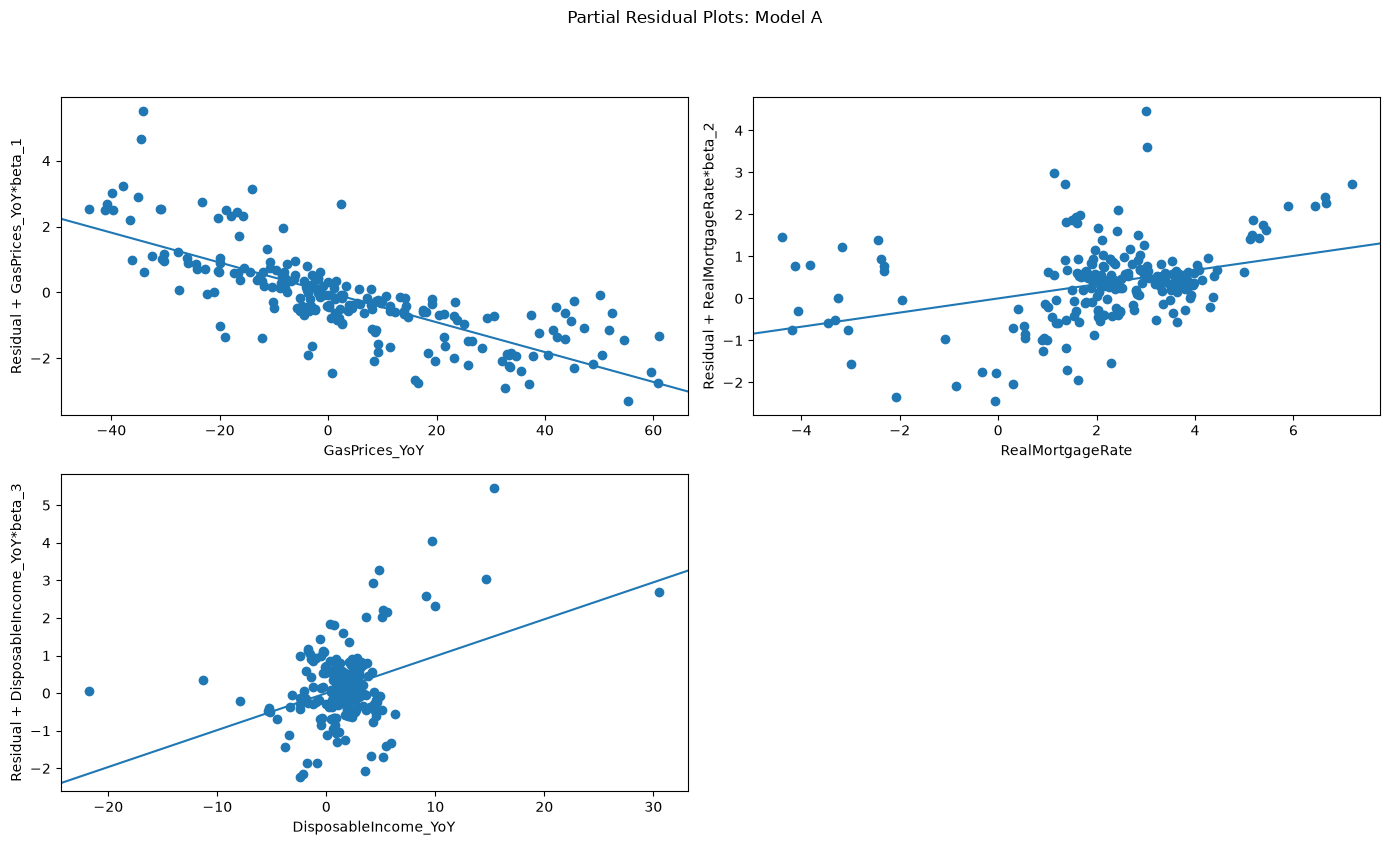

Nonlinear benchmark comparison:
                                 RMSE       MAE
Model                                          
Model A (linear)             1.117007  0.774563
Random Forest (Model A)      1.092011  0.682723
Gradient Boosting (Model A)  1.232002  0.694570
Model B (linear, AR)         0.500688  0.377682
Random Forest (Model B)      0.433970  0.322672
Gradient Boosting (Model B)  0.486795  0.347113


In [12]:
from statsmodels.stats.diagnostic import linear_reset
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Ramsey RESET test
reset_a = linear_reset(baseline_model, power=3, use_f=True)
reset_b = linear_reset(ar_model, power=3, use_f=True)

print("Ramsey RESET test (Model A):")
print(f"F stat = {reset_a.fvalue:.3f}, p-value = {reset_a.pvalue:.4f}")
print("\nRamsey RESET test (Model B):")
print(f"F stat = {reset_b.fvalue:.3f}, p-value = {reset_b.pvalue:.4f}")
print()

# Partial residual plots Model A
fig = plt.figure(figsize=(14,8))
sm.graphics.plot_ccpr_grid(baseline_model, fig=fig)
fig.suptitle("Partial Residual Plots: Model A", y=1.05)
plt.tight_layout()
plt.show()

# Nonlinear benchmark: Random Forest/Gradient Boosting vs. linear models
def fit_and_score(model, cols, label):
    model.fit(train[cols], train[TARGET])
    pred = model.predict(test[cols])
    rmse = np.sqrt(mean_squared_error(test[TARGET], pred))
    mae = mean_absolute_error(test[TARGET], pred)
    return {"Model": label, "RMSE": rmse, "MAE": mae}

nonlinear_results = [
    {"Model": "Model A (linear)", "RMSE": rmse_a, "MAE": mae_a},
    fit_and_score(RandomForestRegressor(n_estimators=500, random_state=42), PREDICTORS, "Random Forest (Model A)"),
    fit_and_score(GradientBoostingRegressor(random_state=42), PREDICTORS, "Gradient Boosting (Model A)"),
    {"Model": "Model B (linear, AR)", "RMSE": rmse_b, "MAE": mae_b},
    fit_and_score(RandomForestRegressor(n_estimators=500, random_state=42), PREDICTORS_AR, "Random Forest (Model B)"),
    fit_and_score(GradientBoostingRegressor(random_state=42), PREDICTORS_AR, "Gradient Boosting (Model B)")
]

print("Nonlinear benchmark comparison:")
print(pd.DataFrame(nonlinear_results).set_index("Model"))

RESET rejects linearity, worth testing a regime-based fix.

# Regime interaction term (Model C)

In [13]:
# Combined crisis/regime dummy: original three EDA defined periods
# along with disinflation/rate hike regime found after residual check (Oct 2022-Jul 2023)

recession_2008_start = pd.to_datetime("2007-12-01")
recession_2008_end = pd.to_datetime("2009-06-01")

covid_start = pd.to_datetime("2020-02-01")
covid_end = pd.to_datetime("2022-06-01")

energy_shock_start = pd.to_datetime("2026-02-01")
energy_shock_end = df["Date"].max()

disinflation_start = pd.to_datetime("2022-10-01")
disinflation_end = pd.to_datetime("2023-07-01")

df["CrisisPeriod"] = (
    df["Date"].between(recession_2008_start, recession_2008_end) |
    df["Date"].between(covid_start, covid_end) |
    df["Date"].between(energy_shock_start, energy_shock_end) |
    df["Date"].between(disinflation_start, disinflation_end)
).astype(int)

print("Months flagged as crisis/regime periods:", df["CrisisPeriod"].sum(), "of", len(df))

# Model C: GasPrices_YoY x CrisisPeriod interaction, added to Model A's predictor set
df["GasPrices_YoY_x_CrisisPeriod"] = df["GasPrices_YoY"] * df["CrisisPeriod"]

PREDICTORS_C = PREDICTORS + ["CrisisPeriod", "GasPrices_YoY_x_CrisisPeriod"]

x_c = sm.add_constant(df[PREDICTORS_C])
y_c = df[TARGET]

# Fit with HAC
model_c = sm.OLS(y_c, x_c).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})
print(model_c.summary())


Months flagged as crisis/regime periods: 60 of 220
                            OLS Regression Results                            
Dep. Variable:         RealWageGrowth   R-squared:                       0.751
Model:                            OLS   Adj. R-squared:                  0.745
Method:                 Least Squares   F-statistic:                     37.23
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           2.26e-27
Time:                        13:18:00   Log-Likelihood:                -279.05
No. Observations:                 220   AIC:                             570.1
Df Residuals:                     214   BIC:                             590.5
Df Model:                           5                                         
Covariance Type:                  HAC                                         
                                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------

Didn't work, testing a narrower disinflation-specific version instead.

# Model C: Narrower Regime Interaction Variants

In [14]:
df["DisinflationPeriod"] = df["Date"].between(disinflation_start, disinflation_end).astype(int)

def fit_interaction_variant(interact_var, regime_var, label):
    interaction_col = f"{interact_var}_x_{regime_var}"
    df[interaction_col] = df[interact_var] * df[regime_var]

    cols = PREDICTORS + [regime_var, interaction_col]
    x = sm.add_constant(df[cols])
    model = sm.OLS(df[TARGET], x).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})

    print(f" --- {label} --- ")
    print(pd.DataFrame({
        "Coef": model.params,
        "Std Err": model.bse,
        "P>|z|": model.pvalues
    }))
    print(f"R-squared: {model.rsquared:.3f}   AIC: {model.aic:.1f}   BIC: {model.bic:.1f}")
    print()
    return model

model_c_mtg_crisis = fit_interaction_variant("RealMortgageRate", "CrisisPeriod", "RealMortgageRate_x_CrisisPeriod (pooled)")
model_c_gas_disinf = fit_interaction_variant("GasPrices_YoY", "DisinflationPeriod", "GasPrices_YoY_x_DisinflationPeriod (narrow)")
model_c_mtg_disinf = fit_interaction_variant("RealMortgageRate", "DisinflationPeriod", "RealMortgageRate_x_DisinflationPeriod (narrow, targeted)")


 --- RealMortgageRate_x_CrisisPeriod (pooled) --- 
                                     Coef   Std Err         P>|z|
const                           -0.208439  0.260883  4.243037e-01
GasPrices_YoY                   -0.043308  0.008523  3.745866e-07
RealMortgageRate                 0.308703  0.100128  2.048556e-03
DisposableIncome_YoY             0.096814  0.033511  3.864323e-03
CrisisPeriod                     0.764595  0.361993  3.467101e-02
RealMortgageRate_x_CrisisPeriod -0.128909  0.079698  1.057761e-01
R-squared: 0.754   AIC: 567.5   BIC: 587.8

 --- GasPrices_YoY_x_DisinflationPeriod (narrow) --- 
                                        Coef   Std Err         P>|z|
const                               0.587811  0.296295  4.727038e-02
GasPrices_YoY                      -0.052941  0.008663  9.875142e-10
RealMortgageRate                    0.073250  0.108130  4.981376e-01
DisposableIncome_YoY                0.105448  0.035430  2.917900e-03
DisinflationPeriod                 -2.220491


*   The narrow disinflation-only dummy massively outperforms the pooled crisis dummy. The R-squared rises by ~0.05 and the AIC drops by roughly 40 points.
*   In both disinflation-narrow models, the main effect is doing most of the work not the interaction term.
*   RealMortgageRate loses significance entirely (p ~ 0.50) once the disinflation period is directly controlled for.
*   RealMortgageRate_x_DisinflationPeriod is the closest of all four interaction terms tested to conventional significance also having the best overall fit.




# Model C: Disinflation Main Effect Only

In [15]:
PREDICTORS_DISINF = PREDICTORS + ["DisinflationPeriod"]

x_disinf = sm.add_constant(df[PREDICTORS_DISINF])
model_disinf_only = sm.OLS(df[TARGET], x_disinf).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})

print(" --- Disinflation Period (main effect only, no interaction) --- ")
print(pd.DataFrame({
    "Coef": model_disinf_only.params,
    "Std Err": model_disinf_only.bse,
    "P>|z|": model_disinf_only.pvalues
}))
print(f"R-squared: {model_disinf_only.rsquared:.3f}   AIC: {model_disinf_only.aic:.1f}   BIC: {model_disinf_only.bic:.1f}")
print()

# Compare against Model A and the best interaction variant so far
comparison = pd.DataFrame({
    "R-squared": [baseline_model.rsquared, model_c_mtg_disinf.rsquared, model_disinf_only.rsquared],
    "AIC": [baseline_model.aic, model_c_mtg_disinf.aic, model_disinf_only.aic],
    "BIC": [baseline_model.bic, model_c_mtg_disinf.bic, model_disinf_only.bic]
}, index=["Model A (baseline)", "RealMortgageRate x DisinflationPeriod", "DisinflationPeriod (main effect only)"])

print("Model Comparison:")
print(comparison)

 --- Disinflation Period (main effect only, no interaction) --- 
                          Coef   Std Err         P>|z|
const                 0.579743  0.296322  5.041071e-02
GasPrices_YoY        -0.052924  0.008654  9.641915e-10
RealMortgageRate      0.075912  0.107831  4.814411e-01
DisposableIncome_YoY  0.106844  0.034971  2.249164e-03
DisinflationPeriod   -2.098849  0.344604  1.124848e-09
R-squared: 0.793   AIC: 527.4   BIC: 544.3

Model Comparison:
                                       R-squared         AIC         BIC
Model A (baseline)                      0.734935  579.845100  593.419610
RealMortgageRate x DisinflationPeriod   0.794558  527.787246  548.149011
DisinflationPeriod (main effect only)   0.793064  527.381119  544.349257



*   The simpler model wins; AIC: 527.4 (main effect only) vs. 527.8 (interaction), BIC: 544.3 vs. 548.1, R-squared: 0.793 vs. 0.795, essentially a tie on fit but an edge for the simpler model on both information criteria.
*   Both disinflation-inclusive models are a massive improvement over Model A and not marginally.
*   RealMortgageRate remains highly non-significant even here, and there is strong evidence now that points to its removal.

Finalized predictor set for Model C:
*   GasPrices_YoY
*   DisposableIncome_YoY
*   DisinflationPeriod









# Expanding Window Backtest

In [16]:
import warnings
from statsmodels.tools.sm_exceptions import SingularMatrixWarning
# Early training windows end before Oct 2022, so DisinflationPeriod is all zeros there and
# collinear with the constant. statsmodels warns on every fit; the pinv solution is still fine
# (the dummy's coefficient is simply undetermined until the regime appears in the sample).
warnings.filterwarnings("ignore", category=SingularMatrixWarning)

PREDICTORS_FINAL = ["GasPrices_YoY", "DisposableIncome_YoY", "DisinflationPeriod"]

# Deliberately earlier than the old 80/20 split, so the out of sample specification
# window spans COVID aftermath, disinflation period, and 2026 energy shock
MIN_TRAIN_FRAC = 0.7

def expanding_window_backtest(cols, label):
    n = len(df)
    min_train = int(n * MIN_TRAIN_FRAC)

    preds, actuals = [], []

    for t in range(min_train, n):
        train_slice = df.iloc[:t]
        test_row = df.iloc[[t]]

        x_train = sm.add_constant(train_slice[cols])
        y_train = train_slice[TARGET]
        x_test = sm.add_constant(test_row[cols], has_constant="add")

        model = sm.OLS(y_train, x_train).fit()
        preds.append(model.predict(x_test).iloc[0])
        actuals.append(test_row[TARGET].iloc[0])

    return {
        "Model": label,
        "RMSE": np.sqrt(mean_squared_error(actuals, preds)),
        "MAE": mean_absolute_error(actuals, preds),
        "OOS points": len(actuals)
    }

def expanding_persistence_backtest():
    n = len(df)
    min_train = int(n * MIN_TRAIN_FRAC)

    preds = df[TARGET].iloc[min_train - 1:n - 1].values
    actuals = df[TARGET].iloc[min_train:n].values

    return {
        "Model": "Persistence",
        "RMSE": np.sqrt(mean_squared_error(actuals, preds)),
        "MAE": mean_absolute_error(actuals, preds),
        "OOS points": len(actuals)
    }

results = [
    expanding_persistence_backtest(),
    expanding_window_backtest(PREDICTORS, "Model A (baseline)"),
    expanding_window_backtest(PREDICTORS_AR, "Model B (AR-augmented)"),
    expanding_window_backtest(PREDICTORS_FINAL, "Model C (DisinflationPeriod)")
]

print(f"Expanding window backtest, starting from {MIN_TRAIN_FRAC:.0%} of the sample:\n")
print(pd.DataFrame(results).set_index("Model"))


Expanding window backtest, starting from 70% of the sample:

                                  RMSE       MAE  OOS points
Model                                                       
Persistence                   0.842877  0.471364          66
Model A (baseline)            1.310311  0.947005          66
Model B (AR-augmented)        0.849059  0.583445          66
Model C (DisinflationPeriod)  0.918986  0.646744          66


No model beats persistence yet.

# Model D: AR + Disinflation Hybrid Backtest

In [17]:
PREDICTORS_HYBRID = PREDICTORS_AR + ["DisinflationPeriod"]

results.append(expanding_window_backtest(PREDICTORS_HYBRID, "Model D (AR + Disinflation Hybrid)"))

print(f"Expanding window backtest, starting from {MIN_TRAIN_FRAC:.0%} of the sample:\n")
print(pd.DataFrame(results).set_index("Model"))

Expanding window backtest, starting from 70% of the sample:

                                        RMSE       MAE  OOS points
Model                                                             
Persistence                         0.842877  0.471364          66
Model A (baseline)                  1.310311  0.947005          66
Model B (AR-augmented)              0.849059  0.583445          66
Model C (DisinflationPeriod)        0.918986  0.646744          66
Model D (AR + Disinflation Hybrid)  0.814369  0.529901          66


First model to beat persistence.

# Model D Lean (drop RealMortgageRate)

In [18]:
PREDICTORS_HYBRID_LEAN = ["GasPrices_YoY", "DisposableIncome_YoY", "RealWageGrowth_Lag1", "DisinflationPeriod"]

results.append(expanding_window_backtest(PREDICTORS_HYBRID_LEAN, "Model D-Lean (AR + Disinflation, no RealMortgageRate)"))

print(f"Expanding window backtest, starting from {MIN_TRAIN_FRAC:.0%} of the sample:\n")
print(pd.DataFrame(results).set_index("Model"))

Expanding window backtest, starting from 70% of the sample:

                                                        RMSE       MAE  \
Model                                                                    
Persistence                                         0.842877  0.471364   
Model A (baseline)                                  1.310311  0.947005   
Model B (AR-augmented)                              0.849059  0.583445   
Model C (DisinflationPeriod)                        0.918986  0.646744   
Model D (AR + Disinflation Hybrid)                  0.814369  0.529901   
Model D-Lean (AR + Disinflation, no RealMortgag...  0.731343  0.480565   

                                                    OOS points  
Model                                                           
Persistence                                                 66  
Model A (baseline)                                          66  
Model B (AR-augmented)                                      66  
Model C (Disinflation



*   Model D-Lean is the better model across the board, beating the full Model D on both RMSE and MAE.
*   Persistence still wins on MAE, but the gap is extremely slim (0.471 vs. 0.481), no other fitted model came as close to that on both metrics simultaneously.
*   Dropping RealMortgageRate removed dead weight that was hurting the model.

Final ranking by RMSE:
*   D-Lean (0.731)
*   D (0.814)
*   Persistence (0.843)
*   B (0.849)
*   C (0.919)
*   A (1.310)












# Regime-Split Error Breakdown (Model D-Lean)

In [19]:
import warnings
from statsmodels.tools.sm_exceptions import SingularMatrixWarning
# Early training windows end before Oct 2022, so DisinflationPeriod is all zeros there and
# collinear with the constant. statsmodels warns on every fit; the pinv solution is still fine
# (the dummy's coefficient is simply undetermined until the regime appears in the sample).
warnings.filterwarnings("ignore", category=SingularMatrixWarning)

def expanding_window_backtest_detailed(cols, label):
    n = len(df)
    min_train = int(n* MIN_TRAIN_FRAC)

    records = []

    for t in range(min_train, n):
        train_slice = df.iloc[:t]
        test_row = df.iloc[[t]]

        x_train = sm.add_constant(train_slice[cols])
        y_train = train_slice[TARGET]
        x_test = sm.add_constant(test_row[cols], has_constant="add")

        model = sm.OLS(y_train, x_train).fit()
        pred = model.predict(x_test).iloc[0]

        records.append({
            "Date": test_row["Date"].iloc[0],
            "Actual": test_row[TARGET].iloc[0],
            "Predicted": pred,
            "DisinflationPeriod": test_row["DisinflationPeriod"].iloc[0]
        })

    detail = pd.DataFrame(records)
    detail["AbsError"] = (detail["Actual"] - detail["Predicted"]).abs()
    detail["SqError"] = (detail["Actual"] - detail["Predicted"]) ** 2
    return detail

detail_d_lean = expanding_window_backtest_detailed(PREDICTORS_HYBRID_LEAN, "Model D-Lean")

# Persistence errors on the same points, for a fair regime-level comparison
min_train = int(len(df) * MIN_TRAIN_FRAC)
persistence_detail = pd.DataFrame({
    "Date": df["Date"].iloc[min_train:].values,
    "Actual": df[TARGET].iloc[min_train:].values,
    "Predicted": df[TARGET].shift(1).iloc[min_train:].values,
    "DisinflationPeriod": df["DisinflationPeriod"].iloc[min_train:].values
})
persistence_detail["AbsError"] = (persistence_detail["Actual"] - persistence_detail["Predicted"]).abs()
persistence_detail["SqError"] = (persistence_detail["Actual"] - persistence_detail["Predicted"]) ** 2

def regime_summary(detail, label):
    summary = detail.groupby("DisinflationPeriod")[["SqError", "AbsError"]].apply(
        lambda g: pd.Series({
            "RMSE": np.sqrt(g["SqError"].mean()),
            "MAE": g["AbsError"].mean(),
            "n": len(g)
        })
    )
    summary.index = summary.index.map({0: "Outside Disinflation", 1: "Inside Disinflation"})
    print(f"--- {label} ---")
    print(summary)
    print()

regime_summary(detail_d_lean, "Model D-Lean")
regime_summary(persistence_detail, "Persistence")

--- Model D-Lean ---
                          RMSE       MAE     n
DisinflationPeriod                            
Outside Disinflation  0.765995  0.502804  56.0
Inside Disinflation   0.494266  0.356027  10.0

--- Persistence ---
                          RMSE       MAE     n
DisinflationPeriod                            
Outside Disinflation  0.869710  0.453393  56.0
Inside Disinflation   0.673127  0.572000  10.0



Still loses to persistence on MAE outside the regime.

# Residual Diagnostics: Model D-Lean

In [20]:
x_dlean = sm.add_constant(df[PREDICTORS_HYBRID_LEAN])
y_dlean = df[TARGET]

model_dlean = sm.OLS(y_dlean, x_dlean).fit()
model_dlean_hac = sm.OLS(y_dlean, x_dlean).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})

print("--- Model D-Lean: OLS vs. HAC standard errors ---")
print(pd.DataFrame({
    "Coef": model_dlean.params,
    "OLS SE": model_dlean.bse,
    "OLS p-value": model_dlean.pvalues,
    "HAC SE": model_dlean_hac.bse,
    "HAC p-value": model_dlean_hac.pvalues
}))
print()

# Breusch-Godfrey, valid here since RealWageGrowth_Lag1 is a lagged DV
bg_stat, bg_pvalue, bg_fstat, bg_fpvalue = acorr_breusch_godfrey(model_dlean, nlags=12, result_object=False)
print("Breusch-Godfrey test (Model D-Lean):")
print(f"LM stat = {bg_stat:.3f}, LM p-value = {bg_pvalue:.4f}")
print(f"F stat = {bg_fstat:.3f}, F p-value = {bg_fpvalue:.4f}")
print()

# Breusch-Pagan, heteroskedasticity check
bp_stat, bp_pvalue, bp_fstat, bp_fpvalue = het_breuschpagan(model_dlean.resid, x_dlean)
print("Breusch-Pagan test (Model D-Lean):")
print(f"LM stat = {bp_stat:.3f}, LM p-value = {bp_pvalue:.4f}")
print(f"F stat = {bp_fstat:.3f}, F p-value = {bp_fpvalue:.4f}")
print()

# Cook's distance
influence_dlean = OLSInfluence(model_dlean)
cooks_d_dlean = influence_dlean.cooks_distance[0]
threshold_dlean = 4 / len(df)

cooks_df_dlean = pd.DataFrame({
    "Date": df["Date"],
    "DisinflationPeriod": df["DisinflationPeriod"],
    "RealWageGrowth": df[TARGET],
    "CooksD": cooks_d_dlean
}).sort_values("CooksD", ascending=False)

print(f"Cook's distance threshold (4/n): {threshold_dlean:.4f}")
print("Top 10 highest-influence points:")
print(cooks_df_dlean.head(10))

--- Model D-Lean: OLS vs. HAC standard errors ---
                          Coef    OLS SE   OLS p-value    HAC SE   HAC p-value
const                 0.356328  0.052239  9.023887e-11  0.088211  5.357216e-05
GasPrices_YoY        -0.030569  0.002600  5.647575e-25  0.006107  5.561217e-07
DisposableIncome_YoY  0.048080  0.011557  4.594433e-05  0.027708  8.269594e-02
RealWageGrowth_Lag1   0.544314  0.037786  2.226394e-33  0.086726  3.467982e-10
DisinflationPeriod   -0.817594  0.210576  1.374816e-04  0.294014  5.422491e-03

Breusch-Godfrey test (Model D-Lean):
LM stat = 78.034, LM p-value = 0.0000
F stat = 9.298, F p-value = 0.0000

Breusch-Pagan test (Model D-Lean):
LM stat = 8.727, LM p-value = 0.0683
F stat = 2.220, F p-value = 0.0679

Cook's distance threshold (4/n): 0.0182
Top 10 highest-influence points:
          Date  DisinflationPeriod  RealWageGrowth    CooksD
146 2020-04-01                   0            7.79  1.375216
158 2021-04-01                   0           -3.53  0.780035



*   April 2020's influence exploded to Cook's D = 1.375, nearly double the second highest point. A single observation this dominant can distort coefficient estimates. Sensitivity check before model is called final.
*   DisposableIncome_YoY loses significance under HAC (p=0.0827), worth running another test with this variable dropped from the model.
*   Breusch-Pagan is no longer significant (p=0.068, vs. Model A's decisive p~0.0000). Adding the AR term and regime dummy improved forecasting and substantially reduced the heteroskedasticity problem in earlier models.
*   Breusch-Godfrey still shows strong residual autocorrelation (p~0.0000, LM stat=78.0). The best performing model in this project hasn't fully resolved the underlying serial dependence, HAC correction keeps inferences valid.
*   March 2022's influence dropped substantially from 0.475 (Model A) to 0.171 here, likely being absorbed by the AR term.
*   2008-11-01 is a newly surfaced influential point, not previously flagged in this project.








# Sensitivity Check: April 2020 / April 2021 Influence

In [21]:
excl_apr2020 = df[df["Date"] != "2020-04-01"]
excl_both = df[~df["Date"].isin(pd.to_datetime(["2020-04-01", "2021-04-01"]))]

def refit(data, label):
    x = sm.add_constant(data[PREDICTORS_HYBRID_LEAN])
    y = data[TARGET]
    return sm.OLS(y, x).fit()

model_excl_apr2020 = refit(excl_apr2020, "Excl. Apr 2020")
model_excl_both = refit(excl_both, "Excl. Apr 2020 & Apr 2021")

coef_comparison = pd.DataFrame({
    "Full Sample": model_dlean.params,
    "Excl. Apr 2020": model_excl_apr2020.params,
    "Excl. Apr 2020 & Apr 2021": model_excl_both.params
})

pval_comparison = pd.DataFrame({
    "Full Sample": model_dlean.pvalues,
    "Excl. Apr 2020": model_excl_apr2020.pvalues,
    "Excl. Apr 2020 & Apr 2021": model_excl_both.pvalues
})

print("Coefficient comparison:")
print(coef_comparison)
print()

print("P-value comparison:")
print(pval_comparison)
print()

print("R-squared comparison:")
print(pd.DataFrame({
    "R-squared": [model_dlean.rsquared, model_excl_apr2020.rsquared, model_excl_both.rsquared]
}, index=["Full Sample", "Excl. Apr 2020", "Excl. Apr 2020 & Apr 2021"]))

Coefficient comparison:
                      Full Sample  Excl. Apr 2020  Excl. Apr 2020 & Apr 2021
const                    0.356328        0.325943                   0.288074
GasPrices_YoY           -0.030569       -0.027597                  -0.022357
DisposableIncome_YoY     0.048080        0.021489                   0.009320
RealWageGrowth_Lag1      0.544314        0.593129                   0.666317
DisinflationPeriod      -0.817594       -0.626480                  -0.426808

P-value comparison:
                       Full Sample  Excl. Apr 2020  Excl. Apr 2020 & Apr 2021
const                 9.023887e-11    1.049097e-12               3.315694e-13
GasPrices_YoY         5.647575e-25    3.031517e-28               3.059392e-24
DisposableIncome_YoY  4.594433e-05    3.010597e-02               2.763668e-01
RealWageGrowth_Lag1   2.226394e-33    1.792519e-47               1.323171e-61
DisinflationPeriod    1.374816e-04    3.942291e-04               5.062073e-03

R-squared comparison:
  


*   DisposableIncome_YoY's significance collapses entirely once these two points are removed. Its coefficient shrinks almost entirely and its p-value goes from significant to completely non-significant. DisposableIncome_YoY's effect was substantially propped up by April 2020's COVID shock and the AR echo in April 2021.
*   The coefficient and p-value of RealWageGrowth_Lag1 gets stronger once the outliers are removed.
*   DisinflationPeriod's coefficient shrinks by almost 50% but its p-value remains solidly significant.
*   GasPrices_YoY stays robust and significant across all three specifications, as it has in all other tests.





# Model D Super-Lean (drop DisposableIncome_YoY)

In [22]:
PREDICTORS_SUPER_LEAN = ["GasPrices_YoY", "RealWageGrowth_Lag1", "DisinflationPeriod"]

results.append(expanding_window_backtest(PREDICTORS_SUPER_LEAN, "Model D Super-Lean (AR + Disinflation only)"))

print(f"Expanding window backtest, starting from {MIN_TRAIN_FRAC:.0%} of the sample:\n")
print(pd.DataFrame(results).set_index("Model"))

Expanding window backtest, starting from 70% of the sample:

                                                        RMSE       MAE  \
Model                                                                    
Persistence                                         0.842877  0.471364   
Model A (baseline)                                  1.310311  0.947005   
Model B (AR-augmented)                              0.849059  0.583445   
Model C (DisinflationPeriod)                        0.918986  0.646744   
Model D (AR + Disinflation Hybrid)                  0.814369  0.529901   
Model D-Lean (AR + Disinflation, no RealMortgag...  0.731343  0.480565   
Model D Super-Lean (AR + Disinflation only)         0.661803  0.424127   

                                                    OOS points  
Model                                                           
Persistence                                                 66  
Model A (baseline)                                          66  
Model B (AR-

Best results, beats persistence on both metrics.

# Residual Diagnostics: Model D Super-Lean

In [23]:
x_superlean = sm.add_constant(df[PREDICTORS_SUPER_LEAN])
y_superlean = df[TARGET]

model_superlean = sm.OLS(y_superlean, x_superlean).fit()
model_superlean_hac = sm.OLS(y_superlean, x_superlean).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})

print("--- Model D Super-Lean: OLS vs. HAC standard errors ---")
print(pd.DataFrame({
    "Coef": model_superlean.params,
    "OLS SE": model_superlean.bse,
    "OLS p-value": model_superlean.pvalues,
    "HAC SE": model_superlean_hac.bse,
    "HAC p-value": model_superlean_hac.pvalues
}))
print()

# Breusch-Godfrey
bg_stat, bg_pvalue, bg_fstat, bg_fpvalue = acorr_breusch_godfrey(model_superlean, nlags=12, result_object=False)
print("Breusch-Godfrey test (Model D Super-Lean):")
print(f"LM stat = {bg_stat:.3f}, LM p-value = {bg_pvalue:.4f}")
print(f"F stat = {bg_fstat:.3f}, F p-value = {bg_fpvalue:.4f}")
print()

# Breusch-Pagan
bp_stat, bp_pvalue, bp_fstat, bp_fpvalue = het_breuschpagan(model_superlean.resid, x_superlean)
print("Breusch-Pagan test (Model D Super-Lean):")
print(f"LM stat = {bp_stat:.3f}, LM p-value = {bp_pvalue:.4f}")
print(f"F stat = {bp_fstat:.3f}, F p-value = {bp_fpvalue:.4f}")
print()

# Cook's distance
influence_superlean = OLSInfluence(model_superlean)
cooks_d_superlean = influence_superlean.cooks_distance[0]
threshold_superlean = 4 / len(df)

cooks_df_superlean = pd.DataFrame({
    "Date": df["Date"],
    "DisinflationPeriod": df["DisinflationPeriod"],
    "RealWageGrowth": df[TARGET],
    "CooksD": cooks_d_superlean
}).sort_values("CooksD", ascending=False)

print(f"Cook's distance threshold (4/n): {threshold_superlean:.4f}")
print("Top 10 highest-influence points:")
print(cooks_df_superlean.head(10))

--- Model D Super-Lean: OLS vs. HAC standard errors ---
                         Coef    OLS SE   OLS p-value    HAC SE   HAC p-value
const                0.384962  0.053703  1.187220e-11  0.092266  3.015503e-05
GasPrices_YoY       -0.029936  0.002691  5.139626e-23  0.005570  7.694234e-08
RealWageGrowth_Lag1  0.601818  0.036471  4.010055e-40  0.066440  1.328531e-19
DisinflationPeriod  -0.628440  0.213230  3.558246e-03  0.226613  5.550988e-03

Breusch-Godfrey test (Model D Super-Lean):
LM stat = 70.512, LM p-value = 0.0000
F stat = 8.019, F p-value = 0.0000

Breusch-Pagan test (Model D Super-Lean):
LM stat = 0.735, LM p-value = 0.8650
F stat = 0.241, F p-value = 0.8675

Cook's distance threshold (4/n): 0.0182
Top 10 highest-influence points:
          Date  DisinflationPeriod  RealWageGrowth    CooksD
158 2021-04-01                   0           -3.53  0.874643
146 2020-04-01                   0            7.79  0.410326
9   2008-11-01                   0            2.40  0.073143
184 2

Clean, all predictors survive HAC, heteroskedasticity fully resolved.

# Regime-Split Error Breakdown (Model D Super-Lean)

In [24]:
detail_superlean = expanding_window_backtest_detailed(PREDICTORS_SUPER_LEAN, "Model D Super-Lean")

regime_summary(detail_superlean, "Model D Super-Lean")
regime_summary(persistence_detail, "Persistence")

--- Model D Super-Lean ---
                          RMSE       MAE     n
DisinflationPeriod                            
Outside Disinflation  0.688299  0.432714  56.0
Inside Disinflation   0.487504  0.376045  10.0

--- Persistence ---
                          RMSE       MAE     n
DisinflationPeriod                            
Outside Disinflation  0.869710  0.453393  56.0
Inside Disinflation   0.673127  0.572000  10.0




*   Model D Super-Lean now beats persistence on both metrics, in both regimes. D-Lean lost to persistence on MAE outside the regime, so dropping DisposableIncome_YoY captured the one weak spot D-Lean had.




## Model Comparison

**Final Model: Model D Super-Lean**
Predictors: 'GasPrices_YoY', 'RealWageGrowth_Lag1', 'DisinflationPeriod'
Model roles: Model A is interpretation only, while Model D Super-Lean is the forecasting model.

### Performance
Expanding-window backtest, 66 OOS points spanning COVID aftermath, the 2022-2023 disinflation period, and the 2026 energy shock.

| Model | RMSE | MAE |
|-------|------|-----|
| Persistence Baseline | 0.843 | 0.471 |
| Model A (baseline) | 1.310 | 0.947 |
| Model B (AR-augmented) | 0.849 | 0.583 |
| Model C (DisinflationPeriod) | 0.919 | 0.647 |
| Model D (AR+Disinflation) | 0.814 | 0.530 |
| Model D Lean | 0.731 | 0.481 |
| **Model D Super-Lean (final)** | **0.662** | **0.424** |

Model D Super-Lean is the only model in this comparison to beat the persistence baseline on both metrics, **21.5% better RMSE, 10.0% better MAE.**

### Predictor Selection Trail
*   **GasPrices_YoY**: significant in every specification tested, the most robust variable in the project.
*   **RealMortgageRate (dropped)**: significant under plain OLS in Model A, but never held up. Removing it improved forecasting accuracy.
*   **DisposableIncome_YoY (dropped)**: flagged "retain with caution" in EDA. Lost significance when AR term and DisinflationPeriod were combined, and sensitivity check showed it was being propped up by two months.  
*   **DisinflationPeriod (added)**: surfaced from Cook's distance and residual diagnostics that revealed an uncoded regime, Oct 2022-Jul 2023.
*   **RealWageGrowth_Lag1**: the largest driver of forecast accuracy in this project.

### Diagnostics on the Final Model
*   HAC correction: all three predictors significant (p < 0.01), the only model where every variable survives cleanly.
*   Breusch-Pagan: p=0.865, no meaningful heteroskedasticity.
*   Breusch-Godfrey: still significant autocorrelation (p<0.0001), but falling with each refinement (83.5 -> 78.0 -> 70.5).
*   Cook's distance: April 2020 and April 2021 remain the most influential points.
*   Regime-split backtest: beats persistence on RMSE and MAE, inside and outside disinflation window.


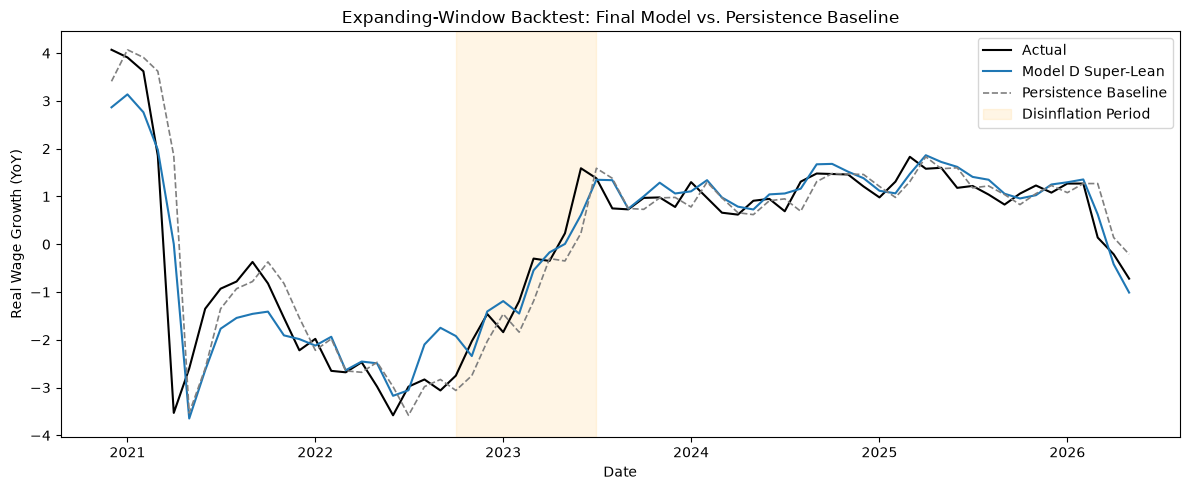

In [25]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(detail_superlean["Date"], detail_superlean["Actual"],
        label="Actual", color="black", linewidth=1.5)
ax.plot(detail_superlean["Date"], detail_superlean["Predicted"],
        label="Model D Super-Lean", color="tab:blue", linewidth=1.5)
ax.plot(persistence_detail["Date"], persistence_detail["Predicted"],
        label="Persistence Baseline", color="tab:gray", linestyle="--", linewidth=1.2)

ax.axvspan(df.loc[df["DisinflationPeriod"] == 1, "Date"].min(),
           df.loc[df["DisinflationPeriod"] == 1, "Date"].max(),
           color="orange", alpha=0.1, label="Disinflation Period")

ax.set_title("Expanding-Window Backtest: Final Model vs. Persistence Baseline")
ax.set_xlabel("Date")
ax.set_ylabel("Real Wage Growth (YoY)")
ax.legend()
plt.tight_layout()
plt.savefig("../docs/backtest.png", dpi=150)
plt.show()

# Stress Test: How Robust Is the Headline Result?

In [26]:
from scipy import stats

def backtest_predictions(data, cols):
    # Same expanding-window loop as above, but takes any dataframe and returns the raw predictions
    n = len(data)
    min_train = int(n * MIN_TRAIN_FRAC)
    preds, actuals = [], []

    for t in range(min_train, n):
        train_slice = data.iloc[:t].dropna(subset=cols)
        test_row = data.iloc[[t]]

        model = sm.OLS(train_slice[TARGET], sm.add_constant(train_slice[cols])).fit()
        preds.append(model.predict(sm.add_constant(test_row[cols], has_constant="add")).iloc[0])
        actuals.append(test_row[TARGET].iloc[0])

    return np.array(actuals), np.array(preds)

def gain_vs_persistence(actuals, preds, persistence):
    # Percent improvement over persistence on RMSE and MAE
    rmse_gain = (1 - np.sqrt(np.mean((actuals - preds) ** 2)) / np.sqrt(np.mean((actuals - persistence) ** 2))) * 100
    mae_gain = (1 - np.mean(np.abs(actuals - preds)) / np.mean(np.abs(actuals - persistence))) * 100
    return rmse_gain, mae_gain

actuals, preds_final = backtest_predictions(df, PREDICTORS_SUPER_LEAN)
persistence = persistence_detail["Predicted"].values
dates = persistence_detail["Date"].values

rmse_gain, mae_gain = gain_vs_persistence(actuals, preds_final, persistence)
print(f"Final model vs. persistence: RMSE {rmse_gain:.1f}% better, MAE {mae_gain:.1f}% better")

Final model vs. persistence: RMSE 21.5% better, MAE 10.0% better


## Dependence on April 2021

In [27]:
# Each month's contribution to the squared-error advantage over persistence
sq_advantage = (actuals - persistence) ** 2 - (actuals - preds_final) ** 2
apr_2021 = pd.to_datetime(dates) == "2021-04-01"

print(f"April 2021 share of the total squared-error advantage: {sq_advantage[apr_2021].sum() / sq_advantage.sum():.0%}")

rmse_gain, mae_gain = gain_vs_persistence(actuals[~apr_2021], preds_final[~apr_2021], persistence[~apr_2021])
print(f"Excluding April 2021: RMSE {rmse_gain:.1f}% better, MAE {mae_gain:.1f}% better")

closer = np.abs(actuals - preds_final) < np.abs(actuals - persistence)
print(f"Months where the final model is closer than persistence: {closer.sum()} of {len(closer)}")

April 2021 share of the total squared-error advantage: 91%
Excluding April 2021: RMSE 4.4% better, MAE 4.9% better
Months where the final model is closer than persistence: 31 of 66


## Diebold-Mariano Test

In [28]:
# Tests whether the average squared-error advantage is different from zero
dm_simple_t = sq_advantage.mean() / (sq_advantage.std(ddof=1) / np.sqrt(len(sq_advantage)))
dm_simple_p = 2 * (1 - stats.norm.cdf(abs(dm_simple_t)))

# Same test with HAC standard errors, since the errors are autocorrelated
dm_hac = sm.OLS(sq_advantage, np.ones(len(sq_advantage))).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})

print(f"Diebold-Mariano p-value (simple): {dm_simple_p:.2f}")
print(f"Diebold-Mariano p-value (HAC):    {dm_hac.pvalues[0]:.2f}")

Diebold-Mariano p-value (simple): 0.29
Diebold-Mariano p-value (HAC):    0.30


## Nowcast vs. True Forecast, and the Dummy's Contribution

In [29]:
# Last month's gas price instead of this month's, so the model only uses information available at forecast time
df["GasPrices_YoY_Lag1"] = df["GasPrices_YoY"].shift(1)

variants = {
    "Final model (same-month gas)": PREDICTORS_SUPER_LEAN,
    "Final model, last month's gas": ["GasPrices_YoY_Lag1", "RealWageGrowth_Lag1", "DisinflationPeriod"],
    "Final model, no DisinflationPeriod": ["GasPrices_YoY", "RealWageGrowth_Lag1"]
}

rows = []
for label, cols in variants.items():
    _, preds = backtest_predictions(df, cols)
    rmse_gain, mae_gain = gain_vs_persistence(actuals, preds, persistence)
    rows.append({"Model": label, "RMSE gain (%)": round(rmse_gain, 1), "MAE gain (%)": round(mae_gain, 1)})

print(pd.DataFrame(rows).set_index("Model"))

                                    RMSE gain (%)  MAE gain (%)
Model                                                          
Final model (same-month gas)                 21.5          10.0
Final model, last month's gas                 6.2           0.4
Final model, no DisinflationPeriod           18.6           3.2


## Disinflation Window: Split Artifact Check and Boundary Sensitivity

In [30]:
# Model A fit on the full sample (no train/test split): residuals inside vs. outside the window
in_window = df["DisinflationPeriod"] == 1
resid_a = baseline_model.resid

print(f"Window months over-predicted by full-sample Model A: {(resid_a[in_window] < 0).sum()} of {in_window.sum()}")
print(f"Mean residual inside the window:  {resid_a[in_window].mean():.2f}")
print(f"Mean residual outside the window: {resid_a[~in_window].mean():.2f}")

Window months over-predicted by full-sample Model A: 10 of 10
Mean residual inside the window:  -1.81
Mean residual outside the window: 0.09


In [31]:
# Shift the window's start and end by up to three months and rerun the backtest
windows = [("2022-07-01", "2023-07-01"),
           ("2022-08-01", "2023-09-01"),
           ("2022-10-01", "2023-04-01"),
           ("2022-10-01", "2023-07-01"),
           ("2022-10-01", "2023-10-01"),
           ("2023-01-01", "2023-07-01")]

rows = []
for start, end in windows:
    shifted = df.copy()
    shifted["DisinflationPeriod"] = shifted["Date"].between(start, end).astype(int)
    _, preds = backtest_predictions(shifted, PREDICTORS_SUPER_LEAN)
    rmse_gain, mae_gain = gain_vs_persistence(actuals, preds, persistence)
    rows.append({"Window": f"{start[:7]} to {end[:7]}", "RMSE gain (%)": round(rmse_gain, 1), "MAE gain (%)": round(mae_gain, 1)})

print(pd.DataFrame(rows).set_index("Window"))

                    RMSE gain (%)  MAE gain (%)
Window                                         
2022-07 to 2023-07           23.3          13.3
2022-08 to 2023-09           23.8          12.4
2022-10 to 2023-04           21.9          10.0
2022-10 to 2023-07           21.5          10.0
2022-10 to 2023-10           21.0           8.0
2023-01 to 2023-07           18.2           3.6
